# 3. Classify New Raw Keystroke Logs

Takes a raw `.jsonl` capture (same schema as training data — one JSON event per line),
rebuilds the same sliding-window features used in training, and runs them through the
saved Random Forest to get a human vs. injected verdict.

This reuses the same pairing/windowing logic as notebook 1 so the features line up exactly
with what the model was trained on.

## Config — point this at the new log you want to classify

In [1]:
RAW_LOG_PATH = "../data/raw/adhi_01.jsonl"   # <-- change this
MODEL_DIR = "../model"                       # Canonical root model directory


## Imports

In [2]:
import glob
import json
import os

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline


## Load the saved model + metadata

In [3]:
clf = joblib.load(os.path.join(MODEL_DIR, "rf_model.joblib"))
with open(os.path.join(MODEL_DIR, "model_meta.json")) as f:
    meta = json.load(f)

feature_cols = meta["feature_columns"]
sentinel = meta["sentinel_fill_value"]
WINDOW = meta["window_size"]
STEP = meta["window_step"]

print("Model expects features:", feature_cols)
print(f"Window={WINDOW}, step={STEP}")


Model expects features: ['mean_dwell_ms', 'std_dwell_ms', 'cv_dwell', 'n_dwell_outliers_excluded', 'mean_flight_ms', 'std_flight_ms', 'cv_flight', 'n_pauses_excluded', 'autorepeat_ratio', 'backspace_ratio', 'events_per_sec', 'n_devices_in_window']
Window=25, step=5


## Feature-building functions

Identical logic to notebook 1's pipeline (kept here so this notebook is self-contained and
runnable on its own — no need to re-run notebook 1 to classify a new file).

In [4]:
FLAG_BREAK_BIT = 0x01
FLAG_E0_BIT = 0x02
VK_BACK = 0x08
VK_DELETE = 0x2E
PAUSE_THRESHOLD_MS = 2000
DWELL_CAP_MS = 2000


def load_raw_file(path: str) -> pd.DataFrame:
    rows = []
    with open(path, encoding="utf-8") as fh:
        for line in fh:
            line = line.strip()
            if not line:
                continue
            rows.append(json.loads(line))
    if not rows:
        raise ValueError(f"{path}: no events found")
    df = pd.DataFrame(rows)
    df["source_file"] = os.path.basename(path)
    for col, default in [
        ("seq", np.nan), ("qpc_ticks", np.nan), ("device_handle", ""),
        ("message", np.nan), ("is_autorepeat", np.nan), ("payload_variant", None),
        ("session_id", os.path.basename(path)), ("subject_id", "unknown"), ("label", "unknown"),
    ]:
        if col not in df.columns:
            df[col] = default
    return df


def clean_session(session: pd.DataFrame, log_prefix: str) -> pd.DataFrame:
    before = len(session)
    dedup_cols = [c for c in ["timestamp_ns", "vkey", "scan_code", "flags"] if c in session.columns]
    session = session.drop_duplicates(subset=dedup_cols).reset_index(drop=True)
    n_dupes = before - len(session)

    n_minority_dropped = 0
    if "device_path" in session.columns and session["device_path"].nunique() > 1:
        counts = session["device_path"].value_counts()
        dominant = counts.idxmax()
        minority_mask = session["device_path"] != dominant
        n_minority_dropped = int(minority_mask.sum())
        session = session[~minority_mask].reset_index(drop=True)

    if n_dupes or n_minority_dropped:
        print(f"  [clean] {log_prefix}: dropped {n_dupes} duplicate events, {n_minority_dropped} minority-device events")
    return session


def pair_dwell_flight(session: pd.DataFrame) -> pd.DataFrame:
    session = session.sort_values("timestamp_ns").reset_index(drop=True)
    open_keys = {}
    last_keyup_ts = None
    records = []

    for idx, row in session.iterrows():
        is_keyup = bool(int(row["flags"]) & FLAG_BREAK_BIT)
        is_extended = bool(int(row["flags"]) & FLAG_E0_BIT)
        key_id = (row["scan_code"], is_extended)

        if not is_keyup:
            flight_ms = ((row["timestamp_ns"] - last_keyup_ts) / 1e6
                         if last_keyup_ts is not None else np.nan)
            open_keys[key_id] = {
                "keydown_ts": row["timestamp_ns"], "vkey": row["vkey"], "scan_code": row["scan_code"],
                "flight_ms": flight_ms, "is_autorepeat": row.get("is_autorepeat", np.nan),
                "device_path": row.get("device_path", None), "seq": row.get("seq", idx),
            }
        else:
            opened = open_keys.pop(key_id, None)
            last_keyup_ts = row["timestamp_ns"]
            if opened is not None:
                dwell_ms = (row["timestamp_ns"] - opened["keydown_ts"]) / 1e6
                records.append({
                    "seq": opened["seq"], "timestamp_ns": opened["keydown_ts"], "vkey": opened["vkey"],
                    "scan_code": opened["scan_code"], "dwell_ms": dwell_ms, "flight_ms": opened["flight_ms"],
                    "is_autorepeat": opened["is_autorepeat"], "device_path": opened["device_path"],
                })
    return pd.DataFrame.from_records(records)


def cv(x: pd.Series) -> float:
    m = x.mean()
    if not np.isfinite(m) or m == 0:
        return np.nan
    return x.std() / m


def windowize(paired: pd.DataFrame, window: int, step: int, meta: dict) -> pd.DataFrame:
    n = len(paired)
    if n < window:
        return pd.DataFrame()

    rows = []
    for start in range(0, n - window + 1, step):
        w = paired.iloc[start:start + window]
        dwell_all = w["dwell_ms"].dropna()
        dwell_outlier_mask = dwell_all > DWELL_CAP_MS
        n_dwell_outliers = int(dwell_outlier_mask.sum())
        dwell = dwell_all[~dwell_outlier_mask]

        flight_all = w["flight_ms"].dropna()
        pause_mask = flight_all > PAUSE_THRESHOLD_MS
        n_pauses = int(pause_mask.sum())
        flight = flight_all[~pause_mask]

        span_s = (w["timestamp_ns"].iloc[-1] - w["timestamp_ns"].iloc[0]) / 1e9
        events_per_sec = (len(w) / span_s) if span_s > 0 else np.nan
        backspace_ratio = w["vkey"].isin([VK_BACK, VK_DELETE]).mean()
        autorepeat_ratio = (w["is_autorepeat"].astype(float).mean()
                             if w["is_autorepeat"].notna().any() else np.nan)
        n_devices = w["device_path"].nunique(dropna=True)

        rows.append({
            **meta, "window_start_seq": w["seq"].iloc[0],
            "mean_dwell_ms": dwell.mean(), "std_dwell_ms": dwell.std(), "cv_dwell": cv(dwell),
            "n_dwell_outliers_excluded": n_dwell_outliers,
            "mean_flight_ms": flight.mean(), "std_flight_ms": flight.std(), "cv_flight": cv(flight),
            "n_pauses_excluded": n_pauses, "autorepeat_ratio": autorepeat_ratio,
            "backspace_ratio": backspace_ratio, "events_per_sec": events_per_sec,
            "n_devices_in_window": n_devices,
        })
    return pd.DataFrame(rows)


def build_windows_for_file(path: str, window: int, step: int) -> pd.DataFrame:
    session = load_raw_file(path)
    session = clean_session(session, os.path.basename(path))
    paired = pair_dwell_flight(session)
    if paired.empty:
        return pd.DataFrame()
    file_meta = {"source_file": session["source_file"].iloc[0], "session_id": session["session_id"].iloc[0]}
    return windowize(paired, window, step, file_meta)

print("Functions defined.")


Functions defined.


## Build features for the new log and classify

In [5]:
windows = build_windows_for_file(RAW_LOG_PATH, WINDOW, STEP)

if windows.empty:
    print(f"Fewer than {WINDOW} paired keystrokes in this file — not enough data for a verdict.")
else:
    X_new = windows[feature_cols].fillna(sentinel)
    proba_injected = clf.predict_proba(X_new)[:, 1]
    pred = (proba_injected >= 0.5).astype(int)

    windows = windows.copy()
    windows["proba_injected"] = proba_injected
    windows["prediction"] = np.where(pred == 1, "injected", "human")

    n_windows = len(windows)
    n_flagged = int(pred.sum())
    flagged_rate = n_flagged / n_windows
    verdict = "INJECTED" if flagged_rate >= 0.5 else "human"

    print(f"{n_windows} windows evaluated ({WINDOW} keystrokes/window, step {STEP})")
    print(f"{n_flagged}/{n_windows} windows flagged as injected ({flagged_rate:.1%})")
    print(f"mean P(injected) = {proba_injected.mean():.3f}")
    print(f"\nVERDICT: {verdict}")

    display(windows[["window_start_seq", "proba_injected", "prediction"]])


134 windows evaluated (25 keystrokes/window, step 5)
0/134 windows flagged as injected (0.0%)
mean P(injected) = 0.028

VERDICT: human


,window_start_seq,proba_injected,prediction
0,1,0.000765,human
1,11,0.004703,human
2,21,0.018858,human
3,31,0.031330,human
4,41,0.045331,human
...,...,...,...
129,1291,0.009593,human
130,1301,0.000619,human
131,1311,0.027006,human
132,1321,0.021122,human


## Plot P(injected) across the session

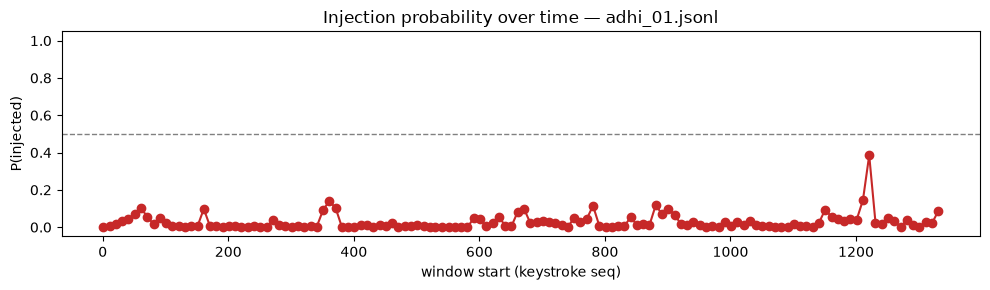

In [6]:
if not windows.empty:
    fig, ax = plt.subplots(figsize=(10, 3))
    ax.plot(windows["window_start_seq"], windows["proba_injected"], marker="o", color="#c62828")
    ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
    ax.set_xlabel("window start (keystroke seq)")
    ax.set_ylabel("P(injected)")
    ax.set_title(f"Injection probability over time — {os.path.basename(RAW_LOG_PATH)}")
    ax.set_ylim(-0.05, 1.05)
    plt.tight_layout()
    plt.show()


## Classify a whole folder of new logs at once

Loops `build_windows_for_file` + the model over every `.jsonl` in a directory and prints one
verdict line per file.

In [7]:
RAW_DIR_TO_SCAN = "../data/raw"   # <-- change this to scan a folder instead of one file

for path in sorted(glob.glob(os.path.join(RAW_DIR_TO_SCAN, "*.jsonl"))):
    w = build_windows_for_file(path, WINDOW, STEP)
    if w.empty:
        print(f"[skip] {os.path.basename(path)}: not enough paired keystrokes")
        continue
    Xw = w[feature_cols].fillna(sentinel)
    p = clf.predict_proba(Xw)[:, 1]
    verdict = "INJECTED" if (p >= 0.5).mean() >= 0.5 else "human"
    print(f"{os.path.basename(path):40s} -> {verdict:9s} (mean P(injected)={p.mean():.3f}, n_windows={len(w)})")


adhi_01.jsonl                            -> human     (mean P(injected)=0.028, n_windows=134)
adhi_02.jsonl                            -> human     (mean P(injected)=0.022, n_windows=135)
adhi_03.jsonl                            -> human     (mean P(injected)=0.012, n_windows=140)
adhi_04.jsonl                            -> human     (mean P(injected)=0.010, n_windows=129)
adhi_05.jsonl                            -> human     (mean P(injected)=0.052, n_windows=139)
donkeykong_01.jsonl                      -> human     (mean P(injected)=0.001, n_windows=87)
donkeykong_02.jsonl                      -> human     (mean P(injected)=0.001, n_windows=90)
donkeykong_03.jsonl                      -> human     (mean P(injected)=0.001, n_windows=83)
flashbird_01.jsonl                       -> human     (mean P(injected)=0.001, n_windows=103)
flashbird_02.jsonl                       -> human     (mean P(injected)=0.002, n_windows=111)
flashbird_03.jsonl                       -> human     (mean P(i